# Airport Secondary Baggage-Inspection Queue: Data-Informed Discrete-Event Simulation

**Reproducible Python notebook — final technical-analysis draft**

**Research question.** Under explicitly assumed arrival intensities and observed manual baggage-check service durations, how many parallel inspection stations are needed to meet an illustrative mean waiting-time target of **0.5 minute (30 seconds)**? How sensitive is that choice to demand and service-duration uncertainty?

This notebook keeps the original **FIFO next-event simulator**, uses an analytical **M/M/c baseline**, and investigates an empirical-service **M/G/c** model. The model is a **hypothetical secondary-inspection queue**, not a validated reproduction of Rotterdam The Hague Airport operations. The source dataset contains service-start/end timestamps, **not arrival-to-queue timestamps**.

**Implementation:** Python, NumPy, pandas, SciPy, matplotlib. **Reproducibility:** deterministic seeds, independent replications, visible assertions, and cross-method comparisons. **Provenance:** developed with AI assistance; student review and final interpretation remain necessary.

## 1. Problem definition, deliverables and three module topics

The decision variable is the number of simultaneously available, identical manual baggage-inspection stations, under assumed arrival intensities. Inputs are arrival rate $\lambda$ (passengers/min), station count $c$, and a multiplier $m$ for observed service durations. Main outputs are mean waiting time $E[W_q]$, the fraction waiting over 0.5 minute, nominal utilisation, and confidence intervals across independent replications.

| Module topic | Application | Where evidenced |
|---|---|---|
| Discrete-event simulation and queueing (primary) | FIFO arrival/departure event loop; M/M/c steady-state benchmark | §§3–5 |
| Input modelling and random variate generation | Poisson/exponential interarrivals; resampling observed service durations | §§3, 6 |
| Monte Carlo methods and law of large numbers | Independent replications, Student-t intervals, RMSE scaling | §§4–8 |

**Scope:** A single shared FIFO waiting line and $c$ interchangeable inspection stations; no abandonment, priorities, staff breaks, full terminal routing, or real queue-arrival observations. Outputs are **conditional planning comparisons** and not operational advice.

## 2. Mathematical model, assumptions and units

In an **M/M/$c$** reference model, interarrival times are exponential with arrival rate $\lambda$; each server has independent exponential service times with rate $\mu$. With $a=\lambda/\mu$ and utilisation $\rho=\lambda/(c\mu)<1$, the Erlang-C steady-state result is

$$P_0=\left[\sum_{k=0}^{c-1}\frac{a^k}{k!}+\frac{a^c}{c!(1-\rho)}\right]^{-1},\quad P_{\rm wait}=\frac{a^cP_0}{c!(1-\rho)},$$

$$E[W_q]=\frac{P_{\rm wait}}{c\mu-\lambda}.$$

For one server, $E[W_q]=\lambda/[\mu(\mu-\lambda)]$. The **M/G/$c$** model retains the Poisson arrival process but samples observed manual baggage-check durations with replacement. Its nominal utilisation is

$$\rho=\frac{\lambda\,m\,E[S]}{c},$$

where $S$ is the measured duration in minutes. **Stable steady state requires $\rho<1$**. We do not apply Erlang-C formulas to the empirical-service case as an exact waiting-time benchmark.

**Units:** arrivals/minute; service time and queue waiting time in minutes; reported source-data descriptive statistics in seconds. All scenarios are synthetic arrival processes; only manual baggage inspection durations are calibrated from observations. Finite-run simulations begin empty and discard a warm-up prefix for customer waiting-time analyses; warm-up bias may remain.

## 3. Simulation algorithm and reproducible environment

In [1]:
# Install only absent dependencies; this cell runs before the notebook imports.
import importlib.util, subprocess, sys
required = {'numpy':'numpy','pandas':'pandas','matplotlib':'matplotlib','scipy':'scipy'}
missing = [pkg for module,pkg in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable,'-m','pip','install','-q',*missing])
print('Environment ready; missing packages installed:',missing or 'none')

Environment ready; missing packages installed: none


In [2]:
# Standalone Colab cell; Python queue engine is identical to src/queue_model.py.
# Source provenance: ChatGPT-generated, human review required.
import math, statistics, csv, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t as student_t

"""Single FIFO queue with parallel identical inspection stations; units: minutes."""
from collections import deque
from dataclasses import dataclass
from math import inf
import random

@dataclass
class Result:
    arrivals: int
    completed: int
    mean_wait: float
    fraction_wait_over_target: float
    mean_queue_length: float
    utilisation: float
    waits: list

def simulate(arrivals, services, servers=2, target_wait=5.0):
    """Deterministic event-trace engine; arrivals and services are equal-length sequences."""
    if servers < 1 or len(arrivals) != len(services):
        raise ValueError("Invalid server count or trace lengths")
    if any(b < a for a,b in zip(arrivals,arrivals[1:])):
        raise ValueError("Arrivals must be sorted")
    if any(s <= 0 for s in services):
        raise ValueError("Service durations must be positive")
    n=len(arrivals)
    if not n:
        return Result(0,0,0,0,0,0,[])
    idle=list(range(servers))
    finish=[inf]*servers
    queue=deque()
    waits=[0.0]*n
    i=0; done=0; now=0.; queue_area=0.; busy_area=0.
    while done<n:
        next_arrival=arrivals[i] if i<n else inf
        next_depart=min(finish)
        t=min(next_arrival,next_depart)
        queue_area+=len(queue)*(t-now)
        busy_area+=sum(f<inf for f in finish)*(t-now)
        now=t
        # Departures before arrivals at tied timestamps.
        departing=[j for j,f in enumerate(finish) if f==now]
        for j in departing:
            finish[j]=inf; done+=1; idle.append(j)
        while i<n and arrivals[i]==now:
            queue.append(i); i+=1
        idle.sort()
        while idle and queue:
            j=idle.pop(0)
            customer=queue.popleft()
            waits[customer]=now-arrivals[customer]
            finish[j]=now+services[customer]
    duration=now  # Time-averaged metrics over [0, final departure], matching browser.
    return Result(n,done,sum(waits)/n,sum(w>target_wait for w in waits)/n,
                  queue_area/duration if duration else 0,
                  busy_area/(servers*duration) if duration else 0,waits)

def random_trace(rate_per_minute, mean_service_minutes, n, seed):
    if rate_per_minute<=0 or mean_service_minutes<=0: raise ValueError("Rates must be positive")
    rng=random.Random(seed); t=0.; arrivals=[]; services=[]
    for _ in range(n):
        t+=rng.expovariate(rate_per_minute)
        arrivals.append(t)
        services.append(rng.expovariate(1/mean_service_minutes))
    return arrivals,services



In [3]:
def mmc_wait(lambda_rate, mu_rate, servers):
    if not 0 < lambda_rate < servers * mu_rate:
        raise ValueError("Requires stable M/M/c parameters")
    a = lambda_rate / mu_rate
    rho = a / servers
    p0 = 1 / (sum(a**k/math.factorial(k) for k in range(servers)) + a**servers/(math.factorial(servers)*(1-rho)))
    pw = a**servers * p0/(math.factorial(servers)*(1-rho))
    return pw/(servers*mu_rate-lambda_rate)

def replication(rate, mean_service, servers, n, seed, warmup=1000):
    arrivals, services = random_trace(rate, mean_service, n + warmup, seed)
    result = simulate(arrivals, services, servers=servers)
    # Warm-up is discarded from customer waiting observations only.
    # Area/time statistics require a separate steady-state window implementation.
    return float(np.mean(result.waits[warmup:])), float(np.mean(np.asarray(result.waits[warmup:]) > 5))

def mean_ci(values, alpha=0.05):
    values = np.asarray(values, dtype=float)
    if len(values) < 2: raise ValueError("At least two replications required")
    avg = float(values.mean())
    half = float(student_t.ppf(1-alpha/2, len(values)-1) * values.std(ddof=1)/np.sqrt(len(values)))
    return avg, avg-half, avg+half


## 4. Verification of the original event simulator

The tests below establish queue order, seed reproducibility, an exact hand-calculated trace, and an analytical **M/M/$c$** benchmark. At equal timestamps, departures are processed before arrivals. Queue-length and busy-time integrals in the event engine are averaged over $[0,\ \text{last departure time}]$; the reported customer-wait confidence intervals use post-warm-up arrivals, not whole-trace time integrals.

**Hand trace:** arrivals (0, 1, 1.5) minutes, services (3, 2, 1) minutes, one station. Waiting times are (0, 2, 3.5) minutes, with mean 1.8333 minutes. In the benchmark, confidence intervals refer to independent run means rather than treating passengers within one run as independent.

In [4]:
hand = simulate([0, 1, 1.5], [3, 2, 1], servers=1)
assert np.allclose(hand.waits, [0, 2, 3.5])
assert simulate([0, 10, 20], [1, 1, 1], servers=1).mean_wait == 0
assert random_trace(0.8, 1, 10, 7) == random_trace(0.8, 1, 10, 7)
print("Hand trace, zero-wait and seed reproducibility: PASS")

Hand trace, zero-wait and seed reproducibility: PASS


In [5]:
rate, mean_service, servers = 0.8, 1.0, 2
samples = [replication(rate, mean_service, servers, 12000, seed=100+i)[0] for i in range(30)]
estimate, lower, upper = mean_ci(samples)
analytic = mmc_wait(rate, 1/mean_service, servers)
print(f"Simulated Wq = {estimate:.4f} min; 95% CI [{lower:.4f}, {upper:.4f}]")
print(f"M/M/c analytical Wq = {analytic:.4f} min")
assert abs(estimate - analytic) < 0.035, "M/M/c comparison outside predeclared 0.035-minute tolerance"

Simulated Wq = 0.1944 min; 95% CI [0.1898, 0.1991]
M/M/c analytical Wq = 0.1905 min


In [6]:
from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
FIGURES = Path('Figures'); RESULTS = Path('Results')
FIGURES.mkdir(exist_ok=True); RESULTS.mkdir(exist_ok=True)
print('Figure and result export directories ready.')

Figure and result export directories ready.


## 5. M/M/$c$ baseline staffing experiment

Independent seeded replications compare one through four stations at the **same assumed arrival rate of 0.8 passengers/minute** and mean one-minute exponential service time. Results describe model-conditional mean waits and the simulated probability of a wait over five minutes. A 95% interval is calculated from independent replication means.

,stations,mean_wait,ci_low,ci_high,p_wait_over_5,utilization_theory
0,1,3.977800,3.752525,4.203075,0.291060,0.800000
1,2,0.193371,0.187432,0.199311,0.000433,0.400000
2,3,0.023441,0.022127,0.024755,0.000000,0.266667
3,4,0.003057,0.002730,0.003383,0.000000,0.200000


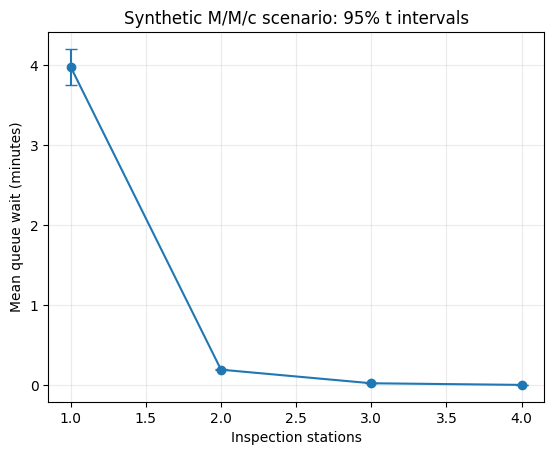

In [7]:
records=[]
for c in [1,2,3,4]:
    if rate >= c/mean_service: continue
    rep=[replication(rate, mean_service, c, 5000, 5000+c*100+i) for i in range(30)]
    w=mean_ci([v[0] for v in rep]); tail=mean_ci([v[1] for v in rep])
    records.append(dict(stations=c, mean_wait=w[0], ci_low=w[1], ci_high=w[2], p_wait_over_5=tail[0], utilization_theory=rate*mean_service/c))
results=pd.DataFrame(records)
display(results)
plt.errorbar(results.stations,results.mean_wait,yerr=[results.mean_wait-results.ci_low,results.ci_high-results.mean_wait],fmt='o-',capsize=4)
plt.xlabel('Inspection stations');plt.ylabel('Mean queue wait (minutes)');plt.title('Synthetic M/M/c scenario: 95% t intervals');plt.grid(alpha=.25);plt.savefig(FIGURES/'mmc_baseline.png',dpi=180,bbox_inches='tight');plt.show()

## 6. Empirical service input calibration (X4)

The [Airport Security Checkpoint Data](https://research.tudelft.nl/en/datasets/airport-security-checkpoint-data/) by Janssen and collaborators document actual security-screening activities at Rotterdam The Hague Airport. The workbook’s field definitions identify **Time Start Baggage Check** and **Time End Baggage Check**; their positive differences are manual baggage-check durations. The project-derived `cleaned_baggage_check_durations.csv` retains source session identifiers and 162 observations after an auditable cleaning process. The two source tabs absent from the documented session table were excluded from the primary extract. See repository `data/README.md` and `data/cleaning_audit.csv` for the extraction rules.

The present notebook retrieves the cleaned CSV from the project repository if no local copy is available; no proprietary API or user credential is needed. **The calibration does not supply arrival rates, staffing arrangements, or measured queue waits.**

Experimental mode samples the observed durations with replacement; this is a **conditional empirical-service M/G/$c$ model**, not a calibrated full airport checkpoint. We also quantify uncertainty in the observed mean and compare the empirical distribution with an exponential density of the same mean.

Clean baggage checks: n=162, mean=59.97s, median=42.00s


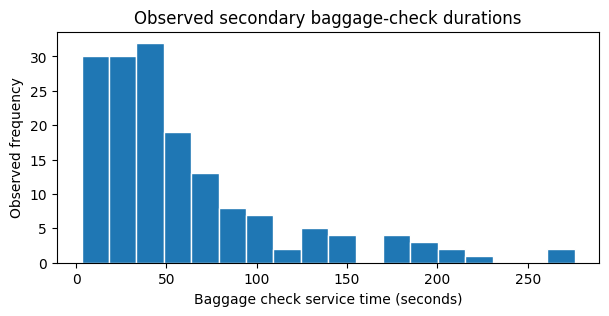

In [8]:
# This public source file must be committed to GitHub along with the notebook.
# GitHub-hosted Colab and local execution both use the same cleaned CSV.
from pathlib import Path
import urllib.request
candidates=[Path('data/cleaned_baggage_check_durations.csv'), Path('../data/cleaned_baggage_check_durations.csv')]
local_path=next((q for q in candidates if q.exists()), None)
url='https://raw.githubusercontent.com/KawanRupasinghe/airport-baggage-queue/main/data/cleaned_baggage_check_durations.csv'
if local_path is not None:
    observed=pd.read_csv(local_path)
else:
    observed=pd.read_csv(io.BytesIO(urllib.request.urlopen(url,timeout=20).read()))
durations_minutes=observed.service_seconds.to_numpy(dtype=float)/60.0
assert {'sheet','service_seconds'}.issubset(observed.columns)
assert observed.sheet.nunique()==13
assert len(durations_minutes)==162
assert np.isclose(observed.service_seconds.sum(), 9715.0), 'Observed durations do not match documented extract' 
assert np.all(np.isfinite(durations_minutes)) and np.all(durations_minutes>0)
print(f'Clean baggage checks: n={len(durations_minutes)}, mean={np.mean(durations_minutes)*60:.2f}s, median={np.median(durations_minutes)*60:.2f}s')
fig,ax=plt.subplots(figsize=(7,3));ax.hist(durations_minutes*60,bins=18,edgecolor='white');ax.set(xlabel='Baggage check service time (seconds)',ylabel='Observed frequency',title='Observed secondary baggage-check durations');plt.show()

In [9]:
def empirical_replication(arrival_rate,stations,n,seed,warmup=500):
    rng=np.random.default_rng(seed)
    interarrival=rng.exponential(1/arrival_rate,size=n+warmup)
    arrival_times=np.cumsum(interarrival).tolist()
    services=rng.choice(durations_minutes,size=n+warmup,replace=True).tolist()
    result=simulate(arrival_times,services,servers=stations)
    post=np.asarray(result.waits[warmup:])
    return float(post.mean()),float(np.mean(post>2.0))

# Replication-level confidence intervals—not passenger-level pseudo-replication.
service_mean=float(durations_minutes.mean())
# Choose rates relative to estimated aggregate service capacity; these rates are assumptions.
records=[]
for load in [0.40,0.65,0.85]:
    for stations in [1,2,3]:
        arrival_rate=load*stations/service_mean
        estimates=[empirical_replication(arrival_rate,stations,2500,seed=1500+int(load*100)*100+stations*40+i) for i in range(24)]
        lo,lower,upper=mean_ci([x[0] for x in estimates])
        records.append(dict(target_utilisation=load,stations=stations,arrival_rate_per_minute=arrival_rate,mean_wait_min=lo,ci_low=lower,ci_high=upper,p_wait_gt_2_min=np.mean([x[1] for x in estimates])))
empirical_results=pd.DataFrame(records)
display(empirical_results.round(4))

,target_utilisation,stations,arrival_rate_per_minute,mean_wait_min,ci_low,ci_high,p_wait_gt_2_min
0,0.40,1,0.4002,0.6021,0.5791,0.6251,0.1105
1,0.40,2,0.8004,0.1697,0.1611,0.1783,0.0151
2,0.40,3,1.2006,0.0685,0.0641,0.0729,0.0025
3,0.65,1,0.6503,1.6741,1.5865,1.7617,0.3094
4,0.65,2,1.3007,0.6864,0.6529,0.7199,0.1154
5,0.65,3,1.9510,0.3599,0.3302,0.3895,0.0410
6,0.85,1,0.8504,5.4267,4.6655,6.1880,0.6155
7,0.85,2,1.7009,2.3125,2.1103,2.5147,0.3940
8,0.85,3,2.5513,1.3311,1.1745,1.4877,0.2554


### 6.1 Service-time distribution and uncertainty

We report mean, median, standard deviation, coefficient of variation, observed upper quantiles and the observed maximum. An exponential density with the *same sample mean* serves only as a visual comparison. We then apply 5,000 seeded nonparametric bootstrap draws for the mean, both by individual observations and by complete observation sessions. These are **uncertainty checks on the selected service sample**; neither gives a population-level guarantee.

,observations,mean_seconds,median_seconds,std_seconds,cv,p90_seconds,p95_seconds,maximum_seconds
0,162,59.969,42.0,54.081,0.902,134.9,183.95,276.0


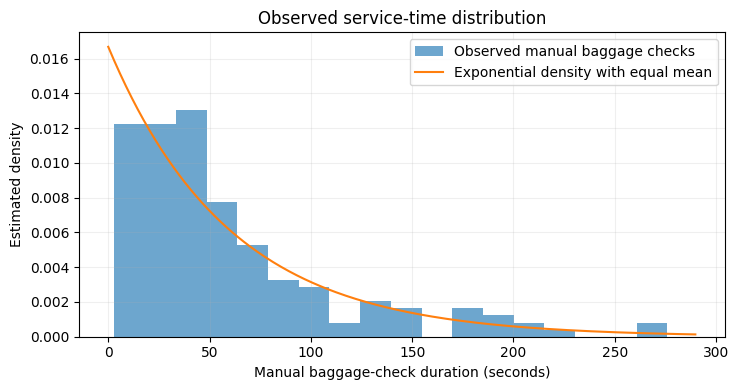

,method,ci_lower_seconds,ci_upper_seconds
0,individual-observation bootstrap,51.957,68.599
1,session-cluster bootstrap,52.603,67.098


In [10]:
# X4: Descriptive statistics and bootstrap uncertainty of observed service durations.
seconds = observed['service_seconds'].to_numpy(dtype=float)
assert len(seconds)==162 and np.all(np.isfinite(seconds)) and np.all(seconds>0)
assert observed['sheet'].nunique()==13
service_stats = pd.DataFrame([{
    'observations':len(seconds), 'mean_seconds':float(seconds.mean()),
    'median_seconds':float(np.median(seconds)), 'std_seconds':float(seconds.std(ddof=1)),
    'cv':float(seconds.std(ddof=1)/seconds.mean()),
    'p90_seconds':float(np.percentile(seconds,90)),
    'p95_seconds':float(np.percentile(seconds,95)),
    'maximum_seconds':float(seconds.max())
}])
display(service_stats.round(3))
service_stats.to_csv(RESULTS/'service_statistics.csv',index=False)
fig, ax=plt.subplots(figsize=(7.5,4))
ax.hist(seconds,bins=18,density=True,alpha=0.65,label='Observed manual baggage checks')
x=np.linspace(0,seconds.max()*1.05,300)
ax.plot(x,np.exp(-x/seconds.mean())/seconds.mean(),label='Exponential density with equal mean')
ax.set(xlabel='Manual baggage-check duration (seconds)',ylabel='Estimated density',title='Observed service-time distribution')
ax.grid(alpha=0.2);ax.legend();fig.tight_layout()
fig.savefig(FIGURES/'observed_service_distribution.png',dpi=180);plt.show()

rng=np.random.default_rng(20261118)
sessions={k:g.service_seconds.to_numpy(dtype=float) for k,g in observed.groupby('sheet')}
keys=list(sessions)
B=5000
iid_means=np.empty(B);cluster_means=np.empty(B)
for b in range(B):
    iid_means[b]=rng.choice(seconds,len(seconds),replace=True).mean()
    selected=rng.choice(keys,size=len(keys),replace=True)
    cluster_means[b]=np.concatenate([sessions[k] for k in selected]).mean()
bootstrap_results=pd.DataFrame([
    {'method':'individual-observation bootstrap','ci_lower_seconds':np.percentile(iid_means,2.5),'ci_upper_seconds':np.percentile(iid_means,97.5)},
    {'method':'session-cluster bootstrap','ci_lower_seconds':np.percentile(cluster_means,2.5),'ci_upper_seconds':np.percentile(cluster_means,97.5)}
])
display(bootstrap_results.round(3))
bootstrap_results.to_csv(RESULTS/'bootstrap_service_mean.csv',index=False)
assert bootstrap_results.ci_lower_seconds.le(seconds.mean()).all()
assert bootstrap_results.ci_upper_seconds.ge(seconds.mean()).all()

### Interpretation of service calibration

The *empirical* service distribution is appropriate for this experiment because it retains observed variability without requiring a fitted parametric family. The number of recorded manual baggage inspections is limited, and the sample may be selected by inspection type, session or staffing. Individual bootstrap resampling assumes observations are exchangeable; resampling entire observation sessions instead gives a descriptive robustness check. Neither procedure proves generalisation to all airport checks.

## 7. Independent verification and Monte Carlo error scaling (X2)

The event-loop implementation is checked using a **separate FCFS algorithm** based on each server's next-available time. This deliberately uses a different algorithmic structure from the event calendar. We compare the exact waiting-time vector for hand traces and independently sampled traces. Then we measure RMSE against the **analytic M/M/1 result** rather than against a resampled simulation-pool mean.

A log–log slope near $-1/2$ supports the expected independent-sampling error rate, but finite-run warm-up bias may flatten the curve. Report the actual measured slope and bias; do not force a desired result.

In [11]:
# Independent FIFO implementation: no reuse of the event calendar.
def reference_fifo_waits(arrivals, services, servers):
    if servers<1 or len(arrivals)!=len(services): raise ValueError('Bad trace')
    availability=[0.0]*servers; waits=[]
    for a,s in zip(arrivals,services):
        j=min(range(servers),key=availability.__getitem__)
        start=max(float(a),availability[j])
        waits.append(start-float(a))
        availability[j]=start+float(s)
    return np.asarray(waits,dtype=float)

cases=[([0,1,1.5],[3,2,1],1),([5,6,6.5],[3,2,1],1),
       ([2,2,2,3.2,8],[1,4,2,1.5,2],2),([0,10,20],[1,1,1],1)]
for a,s,c in cases:
    simulation=simulate(a,s,servers=c)
    np.testing.assert_allclose(simulation.waits,reference_fifo_waits(a,s,c),atol=1e-12)
    assert simulation.completed==simulation.arrivals==len(a)
for c in [1,2,3]:
    rng=np.random.default_rng(200+c)
    arrivals=np.cumsum(rng.exponential(1/.65,250)).tolist()
    services=rng.choice(durations_minutes,250,replace=True).tolist()
    np.testing.assert_allclose(simulate(arrivals,services,c).waits,
                               reference_fifo_waits(arrivals,services,c),atol=1e-10)
print('Independent FCFS traces, conservation and baseline hand tests: PASS')

Independent FCFS traces, conservation and baseline hand tests: PASS


,replications,mean_estimate,bias,rmse
0,2,1.20963,-0.01259,0.10472
1,4,1.21031,-0.01192,0.06972
2,8,1.20562,-0.01660,0.05478
3,16,1.21122,-0.01100,0.04307
4,32,1.21801,-0.00422,0.03041
5,64,1.22125,-0.00097,0.01654


Exact M/M/1 Wq: 1.222222 min; measured RMSE log-log slope: -0.493 (ideal -0.5)


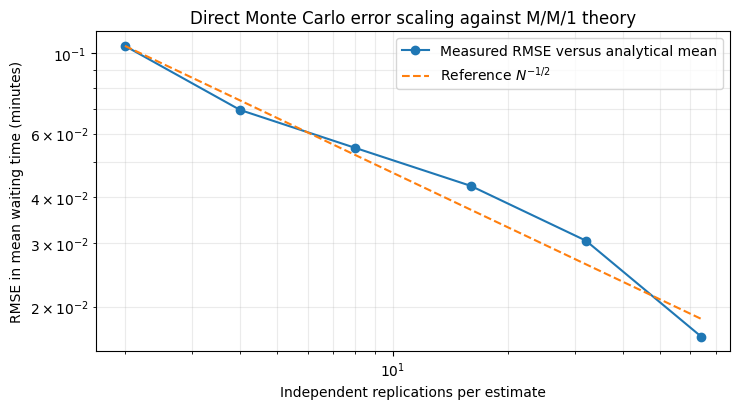

In [12]:
# X2: independent replicated M/M/1 estimates; RMSE measured against exact theory.
# A second single-server recursion is used rather than the event-loop implementation.
def reference_mm1_replication(seed, lam=.55, mu=1.0, warmup=700, recorded=2500):
    rng=random.Random(int(seed)); arrival=0.0; free_at=0.0; total=0.0
    for k in range(warmup+recorded):
        arrival+=rng.expovariate(lam)
        wait=max(0.0,free_at-arrival)
        free_at=max(arrival,free_at)+rng.expovariate(mu)
        if k>=warmup: total+=wait
    return total/recorded

lam,mu=.55,1.0
analytical_wait=mmc_wait(lam,mu,1)
levels=np.array([2,4,8,16,32,64])
num_batches=48
# Independently generated replications; use nested prefixes within each batch.
rep_pool=np.asarray([[reference_mm1_replication(810000+b*100+k)
                      for k in range(int(levels.max()))] for b in range(num_batches)])
error_rows=[]
for m in levels:
    estimates=rep_pool[:,:int(m)].mean(axis=1)
    error_rows.append(dict(replications=int(m),
                           mean_estimate=float(estimates.mean()),
                           bias=float(estimates.mean()-analytical_wait),
                           rmse=float(np.sqrt(np.mean((estimates-analytical_wait)**2)))))
error_table=pd.DataFrame(error_rows)
slope=float(np.polyfit(np.log(error_table.replications),np.log(error_table.rmse),1)[0])
display(error_table.round(5))
print(f'Exact M/M/1 Wq: {analytical_wait:.6f} min; measured RMSE log-log slope: {slope:.3f} (ideal -0.5)')
error_table.to_csv(RESULTS/'x2_direct_analytical_error_scaling.csv',index=False)
fig,ax=plt.subplots(figsize=(7.5,4.2))
ax.loglog(levels,error_table.rmse,'o-',label='Measured RMSE versus analytical mean')
ax.loglog(levels,error_table.rmse.iloc[0]*np.sqrt(levels[0]/levels),'--',label='Reference $N^{-1/2}$')
ax.set(xlabel='Independent replications per estimate',ylabel='RMSE in mean waiting time (minutes)',
       title='Direct Monte Carlo error scaling against M/M/1 theory')
ax.legend();ax.grid(True,alpha=.25,which='both');fig.tight_layout()
fig.savefig(FIGURES/'x2_direct_error_scaling.png',dpi=180);plt.show()
# Guard against invalid outcomes, not against a desired random slope.
assert (error_table.rmse>0).all() and np.isfinite(slope)

## 8. Stability-aware factorial sensitivity study (X5)

A $3\times3\times3$ design independently varies arrival rate $\lambda\in\{0.40,0.65,0.85\}$ passengers/minute, stations $c\in\{1,2,3\}$, and an observed-service-time multiplier $m\in\{0.8,1.0,1.2\}$. For each **stable** configuration, independent replications report mean waiting time, probability of waiting more than 0.5 minute and 95% replication-level confidence intervals.

**Important:** Scenarios with nominal $\rho=\lambda m E[S]/c\ge1$ are *not stable* in infinite-horizon steady state. We do not report their transient finite-run waits as steady-state estimates. A finite warm-up cannot eliminate all bias, especially near saturation.

,arrival_rate,stations,service_multiplier,nominal_utilisation,status,mean_wait_min,ci_low,ci_high,p_wait_gt_0_5
0,0.40,1,0.8,0.3198,STABLE,0.3428,0.3312,0.3543,0.1982
1,0.40,1,1.0,0.3998,STABLE,0.6119,0.5861,0.6376,0.2884
2,0.40,1,1.2,0.4798,STABLE,1.0288,0.9927,1.0650,0.3831
3,0.40,2,0.8,0.1599,STABLE,0.0202,0.0185,0.0219,0.0142
4,0.40,2,1.0,0.1999,STABLE,0.0383,0.0353,0.0413,0.0285
5,0.40,2,1.2,0.2399,STABLE,0.0689,0.0638,0.0740,0.0473
6,0.40,3,0.8,0.1066,STABLE,0.0012,0.0009,0.0015,0.0007
7,0.40,3,1.0,0.1333,STABLE,0.0027,0.0022,0.0032,0.0016
8,0.40,3,1.2,0.1599,STABLE,0.0056,0.0049,0.0064,0.0041
9,0.65,1,0.8,0.5197,STABLE,0.7621,0.7341,0.7900,0.3654


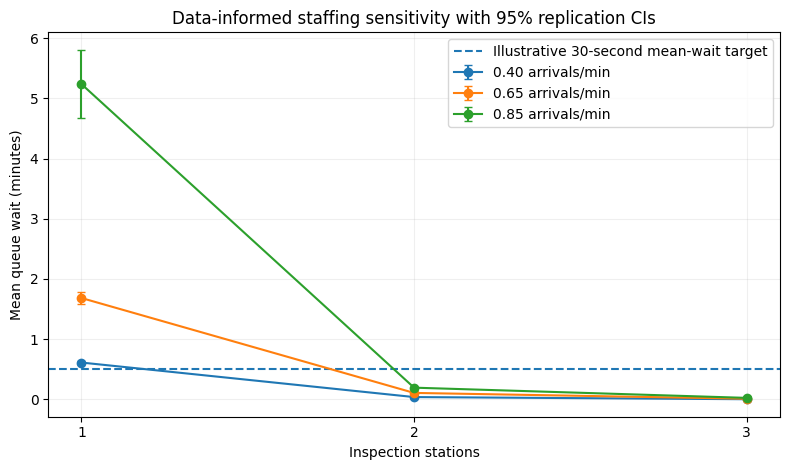

Model-conditional smallest station count for 0.65 arrivals/min and 30-s target: 2
Unstable cases (rho>=1):


,arrival_rate,stations,service_multiplier,nominal_utilisation
20,0.85,1,1.2,1.0195


The finding is hypothetical; queue arrivals and staffing were not observed at the source airport.


In [13]:
def empirical_scaled_replication(arrival_rate, stations, multiplier, seed, n=2400, warmup=550):
    rng=np.random.default_rng(seed)
    arrival_times=np.cumsum(rng.exponential(1/arrival_rate,n+warmup))
    service_times=rng.choice(durations_minutes,size=n+warmup,replace=True)*multiplier
    r=simulate(arrival_times.tolist(),service_times.tolist(),servers=stations,target_wait=0.5)
    waits=np.asarray(r.waits[warmup:],dtype=float)
    assert r.completed==len(arrival_times)
    return float(waits.mean()),float((waits>0.5).mean())

sensitivity=[]
service_mean=float(durations_minutes.mean())
for rate in [0.4,0.65,0.85]:
    for stations in [1,2,3]:
        for multiplier in [0.8,1.0,1.2]:
            rho=rate*service_mean*multiplier/stations
            if rho>=1:
                sensitivity.append(dict(arrival_rate=rate,stations=stations,
                    service_multiplier=multiplier,nominal_utilisation=rho,status='UNSTABLE',
                    mean_wait_min=np.nan,ci_low=np.nan,ci_high=np.nan,p_wait_gt_0_5=np.nan))
                continue
            vals=[empirical_scaled_replication(rate,stations,multiplier,
                    seed=920000+round(rate*100)*10000+stations*1000+round(multiplier*10)*100+j)
                    for j in range(24)]
            point,lower,upper=mean_ci([v[0] for v in vals])
            sensitivity.append(dict(arrival_rate=rate,stations=stations,
                service_multiplier=multiplier,nominal_utilisation=rho,status='STABLE',
                mean_wait_min=point,ci_low=lower,ci_high=upper,
                p_wait_gt_0_5=float(np.mean([v[1] for v in vals]))))
sensitivity_results=pd.DataFrame(sensitivity)
display(sensitivity_results.round(4))
sensitivity_results.to_csv(RESULTS/'x5_stability_aware_sensitivity.csv',index=False)
assert int((sensitivity_results.status=='UNSTABLE').sum())==1
# Constant service multiplier 1.0; compare capacity without changing demand.
base=sensitivity_results.query("service_multiplier == 1.0 and status == 'STABLE'").copy()
fig,ax=plt.subplots(figsize=(8.0,4.8))
for rate,group in base.groupby('arrival_rate'):
    group=group.sort_values('stations')
    ax.errorbar(group.stations,group.mean_wait_min,
        yerr=[group.mean_wait_min-group.ci_low,group.ci_high-group.mean_wait_min],
        fmt='o-',capsize=3,label=f'{rate:.2f} arrivals/min')
ax.axhline(0.5,linestyle='--',label='Illustrative 30-second mean-wait target')
ax.set(xlabel='Inspection stations',ylabel='Mean queue wait (minutes)',
       title='Data-informed staffing sensitivity with 95% replication CIs',xticks=[1,2,3]);
ax.legend();ax.grid(alpha=.2);fig.tight_layout()
fig.savefig(FIGURES/'x5_staffing_sensitivity.png',dpi=180);plt.show()
# Illustrative staffing classification with uncertainty, not airport operating advice.
choice=base.loc[np.isclose(base.arrival_rate,.65)].sort_values('stations')
qualifying=choice[choice.ci_high<=.5]
minimum_stations=int(qualifying.stations.iloc[0]) if len(qualifying) else None
print('Model-conditional smallest station count for 0.65 arrivals/min and 30-s target:',minimum_stations)
print('Unstable cases (rho>=1):')
display(sensitivity_results[sensitivity_results.status=='UNSTABLE'][['arrival_rate','stations','service_multiplier','nominal_utilisation']].round(4))
print('The finding is hypothetical; queue arrivals and staffing were not observed at the source airport.')

### Sensitivity interpretation and decision rule

Compare station counts **at fixed arrival demand and fixed service multiplier**. A scenario with $\rho\ge1$ is flagged **UNSTABLE** and excluded from steady-state staffing comparisons, even if a finite run produces a finite average. The illustrative target is 30 seconds mean queue wait; the smallest station count with the **upper 95% replication-confidence bound** no greater than 0.5 minute is selected among tested choices.

These intervals reflect Monte Carlo replication error **conditional on the model**. They do not include uncertainty about the true passenger arrival rate, the representativeness of the selected service sample, or the assumed pooled-queue configuration. Higher-utilisation stable scenarios may exhibit residual warm-up bias and wide intervals.

## 9. Discussion, validity threats and computational cost

**Scientific interpretation.** Additional stations reduce the chance that all servers are busy when another passenger arrives. When load approaches capacity, waiting times can grow nonlinearly. Under the observed positive skew in manual baggage-check durations, empirical-service simulation is informative because an exponential model with the same mean is not necessarily an adequate representation of the service-time tail.

**Construct validity.** Measured service durations come from selected manual baggage checks. The hypothetical shared FIFO queue, interchangeable staffing stations, Poisson arrivals and the waiting-time target are study assumptions; none are observed in this dataset. The output is not a prediction of actual airport wait time. Duration records may be correlated within sessions; the bootstrap analyses explore, but do not fully resolve, this limitation.

**Internal validity.** Analytic M/M/c checks, hand event traces, a second independently coded FIFO reference, passenger conservation and independent-seed replications triangulate correctness. Monte Carlo uncertainty differs from bias due to empty initial conditions; the error-scaling plot should be interpreted together with measured bias.

**Reproducibility and performance.** Random seeds are fixed and reported, and every scenario is generated from explicit parameters. The event loop advances from one arrival/departure to the next—**there is no time-step stability or convergence parameter**. Queue stability instead depends on $\rho<1$. Small-model runs execute rapidly in Python; see the displayed notebook execution timings for actual performance. Browser–notebook comparison is based on the same fixed event trace, not identical pseudorandom streams.

**Conclusion.** The project evaluates hypothetical secondary-inspection capacity decisions under documented assumptions. No regulatory or operational staffing guarantee is implied.

## 10. References and provenance

[1] S. Janssen, R. van der Sommen, A. Dilweg, and A. Sharpanskykh, “Data-Driven Analysis of Airport Security Checkpoint Operations,” *Aerospace*, vol. 7, no. 6, art. 69, 2020. https://doi.org/10.3390/aerospace7060069

[2] S. Janssen *et al.*, *Airport Security Checkpoint Data*, TU Delft / 4TU.ResearchData, 2020. https://research.tudelft.nl/en/datasets/airport-security-checkpoint-data/ . Source observations and derived CSV are credited under CC BY 4.0.

[3] A. Knol, A. Sharpanskykh, and S. Janssen, “Analyzing airport security checkpoint performance using cognitive agent models,” *Journal of Air Transport Management*, vol. 75, pp. 39–50, 2019.

[4] J. D. C. Little, “A Proof for the Queuing Formula: $L=\lambda W$,” *Operations Research*, vol. 9, no. 3, pp. 383–387, 1961.

[5] D. Gross, J. F. Shortle, J. M. Thompson, and C. M. Harris, *Fundamentals of Queueing Theory*, 4th ed., Wiley, 2008.

[6] A. M. Law, *Simulation Modeling and Analysis*, 5th ed., McGraw-Hill, 2015.

[7] P. Heidelberger and P. D. Welch, “Simulation Run Length Control in the Presence of an Initial Transient,” *Operations Research*, vol. 31, no. 6, pp. 1109–1144, 1983.

The project software and prose were developed with AI assistance. All sources and numeric conclusions should be reviewed by the student. The public repository is not a substitute for the full academic bibliography or AI-use log.

### Export figures and result tables

The final cell packages all chart images and numeric CSV results for use in the report. It leaves the notebook itself intact; **do not substitute the ZIP for the submitted `.ipynb` file**.

In [14]:
with ZipFile('airport_queue_validation_outputs.zip','w',ZIP_DEFLATED) as bundle:
    for folder in [FIGURES,RESULTS]:
        for file in sorted(folder.glob('*')):
            if file.is_file():bundle.write(file,arcname=str(file))
print('Exported Figures and Results to airport_queue_validation_outputs.zip')

Exported Figures and Results to airport_queue_validation_outputs.zip
